# Python Seminar C — Data & Visualization

- NumPy arrays, slicing, boolean masks
- Plotting with Matplotlib
- Tiny bit of Scipy





Welcome! This single notebook combines content from three topics you’ll use a lot in data work:

- **NumPy** (working with fast numeric arrays)
- **Matplotlib** (making simple plots)
- **Scipy** (statistics and linear algebra)

### How this notebook is organized
1. A short title cell before each module that shows which original notebook the cells came from.
2. **All original cells are preserved** exactly as they were (including outputs).
3. At the very end, you’ll find **Extra General Exercises** with simple, beginner‑friendly instructions.

### What you’ll learn today
- Create and manipulate arrays with **NumPy**   
- Visualize data with **Matplotlib**
- Tiny bit of **Scipy** statistics

---


### Tips for success
- Run cells one by one. If something breaks, read the error message slowly—it’s just Python telling you where to look.
- Use `Shift+Enter` to run a cell.
- If a library import fails, try installing it in your environment (for example: `pip install numpy pandas matplotlib`).



# Introduction to Numpy (tutorial)
This notebook is about Numpy, Python's core library for numeric computing. Knowing how to use Numpy is *essential* in domains such as machine learning, neuroimaging analysis, and image processing.

## Contents
1. The *nd*array
2. Indexing
3. Array math
4. Broadcasting

Let's start by importing numpy, which is commonly done as follows:

In [ ]:
import numpy as np

## The *ndarray*
The most important feature of Numpy is it's core data structure: the numpy *ndarray* (which stands for *n*-*d*imensional array, referring to the fact that the array may be of any dimension: 1D, 2D, 3D, 180D ... *n*D). This is, just like basic lists/dictionaries/integers/tuples, a data structure with its own syntax, operations, and methods, as we will explain below.

### Python lists vs. numpy arrays
Basically, numpy arrays are a lot like Python lists. The major difference, however, is that *numpy arrays may contain only a single data-type*, while Python lists may contain different data-types within the same list.

Let check this out:

In [ ]:
# Python lists may contain mixed data-types: an integer, a float, a string, a list
python_list = [1, 2.5, "whatever", [3, 4, 5]]

for value in python_list:

    print("%s is a: %s" % (str(value), type(value)))

1 is a: <class 'int'>
2.5 is a: <class 'float'>
whatever is a: <class 'str'>
[3, 4, 5] is a: <class 'list'>


Unlike Python lists, numpy only allows entries of the same data-type. This difference between Python lists and numpy arrays is basically the same as R lists (allow multiple data-types) versus R matrices/arrays (only allow one data type), and is also the same as MATLAB cells (allow multiple data-types) versus MATLAB matrices (only allow one data type).

In fact, if you try to make a numpy array with different data-types, numpy will force the entries into the same data-type (in a smart way), as is shown in the example below:

In [ ]:
# Importantly, you often specify your arrays as Python lists first, and then convert them to numpy
to_convert_to_numpy = [1, 2, 3.5]               # specify python list ...
numpy_array = np.array(to_convert_to_numpy)     # ... and convert ('cast') it to numpy

for entry in numpy_array:

    print(entry)
    print('this is a: %s \n' % type(entry))

1.0
this is a: <class 'numpy.float64'> 

2.0
this is a: <class 'numpy.float64'> 

3.5
this is a: <class 'numpy.float64'> 



As you can see, Numpy converted our original list (to_convert_to_numpy), which contained both integers and floats, to an array with only floats! You might think that such a data structure that only allows one single data type is not ideal. However, the very fact that it only contains a single data-type makes operations on numpy arrays extremely fast. For example, loops over numpy arrays are often way faster than loops over python lists. This is because, internally, Python has to check the data-type of each loop entry before doing something with that entry. Because numpy arrays one allow a single data-type, it only has to check for the entries' data type **once**. If you imagine looping over an array or list of length 100,000, you probably understand that the numpy loop is way faster.

Let's check out the speed difference between Python list operations and numpy array operations:

In [ ]:
# %timeit is a cool 'feature' that you can use in Notebooks (no need to understand how it works)
# it basically performs a computation that you specify a couple of times and prints how long it took on average
results_python = %timeit -o [x * 2 for x in range(0, 100000)]

6.25 ms ± 105 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


And now let's do the same with numpy:

In [ ]:
results_numpy = %timeit -o np.arange(0, 10000) * 2

ratio = results_python.average / results_numpy.average
print("Numpy is %i times faster than base Python!" % ratio)

15.2 µs ± 2.98 µs per loop (mean ± std. dev. of 7 runs, 100000 loops each)
Numpy is 411 times faster than base Python!


You see that Numpy *much* faster! This really matters when you start doing more complex operations or large arrays!

### Creating numpy arrays
As shown an earlier example, numpy arrays can be created as follows:

1. Define a Python list, e.g. `my_list = [0, 1, 2]`
2. Convert the list to a numpy array, e.g. `numpy_array = np.array(my_list)`

Importantly, a simple Python list will be converted to a 1D numpy array, but a nested Python list will be converted to a 2D (or even higher-dimensional array). Nesting is simply combining different lists, separated by commans, as is shown here:

In [ ]:
my_list = [1, 2, 3]
my_array = np.array(my_list)

print("A 1D (or 'flat') array:")
print(my_array, '\n')

my_nested_list = [[1, 2, 3],
                  [4, 5, 6],
                  [7, 8, 9]]

my_2D_array = np.array(my_nested_list)
print("A 2D array:")
print(my_2D_array)

A 1D (or 'flat') array:
[1 2 3] 

A 2D array:
[[1 2 3]
 [4 5 6]
 [7 8 9]]


<div class='alert alert-warning'>
    <b>ToDo</b>: Create the following 1D array:

\begin{align}
\begin{bmatrix}
5 & 3 & 2 & 8 & 9
\end{bmatrix}
\end{align}

and store it in a variable named <tt>vec</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
#raise NotImplementedError()

[5 3 2 8 9]


In [ ]:
""" Tests the above ToDo. """
if 'vec' not in dir():
    raise ValueError("You haven't created the variable 'vec' yet!")

if type(vec) != np.ndarray:
    raise ValueError("vec is not a numpy array!")

if vec.ndim != 1:
    raise ValueError("vec is not a 1D array!")

if vec.tolist() != [5, 3, 2, 8, 9]:
    raise ValueError("vec does not have the right contents ...")

print("Yay!")

Yay!


<div class='alert alert-warning'>
    <b>ToDo</b>:
    
Create the following matrix (2D array):

\begin{align}
\begin{bmatrix}
5 & 2 & 8 \\
8 & 2 & 1 \\
4 & 4 & 4 \\
1 & 2 & 3
\end{bmatrix}
\end{align}

and store it in a variable named <tt>arr_2d</tt>. Hint: start by creating a nested python list (like we did with the <tt>my_nested_list</tt> variable) and then convert it to numpy.
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

[[5 2 8]
 [8 2 1]
 [4 4 4]
 [1 2 3]]


In [ ]:
""" Tests the above ToDo. """
if type(arr_2d) != np.ndarray:
    raise ValueError("arr_2d is not a numpy array!")

if arr_2d.shape != (4, 3):
    raise ValueError("arr_2d does not have the right shape!")

print("Yes! Well done!")

Yes! Well done!


<div class='alert alert-warning'>
    <b>ToDo</b> (optional): Let's try something more difficult! Create a 3D array with dimensions $2 \times 2 \times 2$ with consecutive numbers starting at 1 and store this in a variable named <tt>arr_3d</tt>. So <tt>arr_3d[0, 0, 0]</tt> should evaluate to 1, <tt>arr_3d[0, 0, 1]</tt> should evaluate to 2, <tt>arr_3d[0, 1, 0]</tt> evaluates to 3, etc.
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
if arr_3d.shape != (2, 2, 2):
    raise ValueError("The array does not have the right dimensions!")

if arr_3d[0, 0, 0] != 1:
    raise ValueError("Hmm, something went wrong ...")

if arr_3d[0, 0, 1] != 2:
    raise ValueError("Hmm, something went wrong ...")

if arr_3d[1, 1, 1] != 8:
    raise ValueError("Hmm, something went wrong ...")

As you can imagine, creating numpy arrays from nested lists becomes cumbersome if you want to create (large) arrays with more than 2 dimensions. There are, fortunately, a lot of other ways to create ('initialize') large, high-dimensional numpy arrays. One often-used method is to create an array with zeros using the numpy function `np.zeros`. This function takes one (mandatory) argument, which is a tuple with the dimensions of your desired array:

In [ ]:
my_desired_dimensions = (2, 5) # suppose I want to create a matrix with zeros of size 2 by 5
my_array = np.zeros(my_desired_dimensions)

print(my_array)

<div class='alert alert-warning'>
    <b>ToDo</b>: Using the <tt>np.zeros</tt> function, create a five dimensional array of shape $2 \times 3 \times 5 \times 3 \times 7$ and store it in a variable named <tt>array_5d</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_create_array_with_zeros
test_create_array_with_zeros(array_5d)

Using arrays with zeros is often used in what is called 'pre-allocation', in which you create an 'empty' array with only zeros and for example, 'fill' that array in a loop.

Below, we show you an example in which we pre-allocate an array with 5 zeros, and fill that in a for-loop with the squares of 1 - 5. Try to understand how it works! (You have to do something similar in the next ToDo!)

In [ ]:
my_array = np.zeros(5)

print('Original zeros-array')
print(my_array)

for i in range(5):  # notice the range function here! This loop now iterates over [0, 1, 2, 3, 4]
    number_to_calculate_the_square_of = i + 1
    my_array[i] = number_to_calculate_the_square_of ** 2

print('\nFilled array')
print(my_array)

<div class='alert alert-warning'>
<b>ToDo</b>: Write a loop in which you fill each value in the variable <tt>my_array2</tt> with the value 1 divided by the current index plus one. So, suppose the index (usually <tt>i</tt>, like the last example) is 3, then you should fill <tt>my_array2</tt> at index <tt>i</tt> with <tt>1 / (3 + 1)</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
my_array2 = np.zeros(8)

# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_fill_array_with_complement
test_fill_array_with_complement(my_array2)

In addition to `np.zeros`, you can create numpy arrays using other functions, like `np.ones` and `random` from the `np.random` module:

In [ ]:
ones = np.ones((5, 10)) # create an array with ones
print(ones, '\n')

rndom = np.random.random((5, 10)) # Create an array filled with random values (0 - 1 uniform)
print(rndom)

## Numpy indexing
Indexing (extracting a single value of an array) and slicing (extracting multiple values - a subset - from an array) of numpy arrays is largely the same as with regular Python lists and data structures from other scientific computing languages such as R and MATLAB. Let's check out a couple of examples of a 1D array:

In [ ]:
my_array = np.arange(10, 21)  # numpy equivalent of list(range(10, 21))
print('Full array:')
print(my_array, '\n')

In [ ]:
print("Index the first element:")
print(my_array[0])

In [ ]:
print("Index the second-to-last element:")
print(my_array[-2])

In [ ]:
print("Slice from 5 until (not including!) 8")
print(my_array[5:8])

In [ ]:
print("Slice from beginning until 4")
print(my_array[:4])

Setting values in numpy arrays works the same way as lists:

In [ ]:
my_array = np.arange(10, 21)
my_array[0] = 10000
print(my_array)

my_array[5:7] = 0
print(my_array)

<div class='alert alert-warning'>
    <b>ToDo</b> (1 point): In the array <tt>my_array</tt> below, set all odd indices (i.e., the first element, the third element, the fifth element, etc.) to the value <tt>0.0</tt> <em>in a single statement using a slice</em> (i.e., not a for-loop).
</div>

In [ ]:
""" Implement the ToDo here. """
my_array = np.arange(3, 25)

# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
''' Tests the above ToDo. '''
from tests import test_set_odd_indices_to_zero
test_set_odd_indices_to_zero(my_array)

### Multidimensional indexing
Often, instead of working on and indexing 1D array, we'll work with multi-dimensional (>1D) arrays. Indexing multi-dimensional arrays is, again, quite similar to other scientific computing languages.

Like indexing Python lists, indexing multidimensional numpy arrays is done with square brackets `[]`, in which you can put as many comma-delimited numbers as there are dimensions in your array.

For example, suppose you have a 2D array of shape $3 \times 3$ and you want to index the value in the first row and first column. You would do this as follows:

In [ ]:
my_array = np.zeros((3, 3)) # 3 by 3 array with zeros
indexed_value = my_array[0, 0]
print("Value of first row and first column: %.1f" % indexed_value)

<div class='alert alert-warning'>
<b>ToDo</b>: Using multidimensional indexing, set the value in the last row and last column of the 2D array <tt>my_array</tt> to <tt>1.0</tt>. In other words, set the value in the lower-right "corner" of the 2D array to 1.0.
</div>

In [ ]:
""" Implement the ToDo here. """
my_array = np.zeros((3, 3))

print(my_array)

# ToDo: set the value in the lower right corner to 1

# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the ToDo above. """
from tests import test_set_lower_right_value_to_one
test_set_lower_right_value_to_one(my_array)

In addition to setting specific slices to specific values, you can also extract sub-arrays using slicing/indexing. An important construct here is that you can use a single colon `:` to select all values from a particular dimension. For example, if you want to select all column-values (second dimension) from only the first row (first dimension), do this:

```
some_2d_arr[0, :]
```

We'll show you some examples below:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

print(my_array, '\n')

all_column_values_from_first_row = my_array[0, :]
print('First row')
print(all_column_values_from_first_row, '\n')

all_row_values_from_first_col = my_array[:, 0]
print('First column')
print(all_row_values_from_first_col)

So far, we only talked about 2D arrays, which are relatively easy to 'understand'. In neuroimaging, however, we usually work with 3D, 4D, or even higher-dimensional arrays. These arrays are great for organizing data, but they are somewhat unintuitive. This takes some time to get used to!

To get you used to thinking in more than 2 (or 3) dimensions, consider the following scenario. Suppose that a researcher wants to test the efficacy of a particular medicine against high blood pressure. To do so, she/he measures the (average systolic) blood pressure of a group of twenty subjects every hour for 30 days when they're not on the medication. The same subjects are then again measured for another 30 days, but then when they're on medication.

After this period of data collection, the researcher has $20\ \mathrm{(subjects)}\ \times\ 24\ \mathrm{(hours)}\ \times\ 30\ \mathrm{(days)}\ \times\ 2\ \mathrm{(conditions: off/on)} = 28800$ measurements! We can then organize the data in a 4D array, in which each factor (subjects/hours/days/conditions) represents a separate dimension (also called "axis") of our array!\*

---
\* Note that this type of data is perhaps best represented in a "table-like" structure, such as a Dataframe in R or a Pandas DataFrame, the Python-equivalent of R's dataframe). But you can ignore that for the sake of this example.

So, let's generate some random data (from a normal distribution to generate 'realistic' blood pressure data) that could represent this blood pressure dataset:

In [ ]:
np.random.seed(42)  # this is not important for now
bp_data = np.random.normal(loc=100, scale=5, size=(20, 24, 30, 2))

(Note that we're not printing the `bp_data` variable here, because it's way too much to visualize/interpret at once anyway!)

Now, suppose I would want to extract the blood pressure of subject 5 at 09.00 (AM) in the morning at day 21 when he/she was *not* on medication. In that case, I would do:

In [ ]:
# Note that I count midnight as the first measurement
this_particular_datapoint = bp_data[4, 8, 20, 0]
print("Blood pressure of participant 5 at 09.00 (AM) on day 21 in "
      "the no-medication (off) condition is %.3f" % this_particular_datapoint)

# Also, remember that Python is zero-based, so e.g. participant 5 is indexed by index 4!

Try to remember this: *in multidimensional arrays, each dimension (axis) represents a different "attribute" of your data (e.g. subjects, time, condition, etc.)*. This concept is very important to understand in, for example, functional MRI analysis (which revolves around 4D data: 3 spatial dimensions and 1 time dimension)!

<div class='alert alert-warning'>
<b>ToDo</b>: Consider the blood-pressure dataset again. In the code-cell below, extract from all participants all data from day 18 in the medication ("on") condition. You'll have to use slices with the single <tt>:</tt>! Store the results of your index-operation in the variable <tt>day_18_condition_on</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_bloodpressure_index
test_bloodpressure_index(day_18_condition_on)

Multidimensional indexing using slices (especially the single colon `:` slice, i.e., selecting everything) is very common in scientific programming such as neuroimaging analyses. There is, however, yet another way of (multidimensional) indexing called "boolean indexing".

In this type of indexing, you index an array with a boolean array (i.e. array with True and False values) of the same shape. Basically, when you're indexing the array `my_array` with boolean array `bool_array`, you're saying: "give me all values in `my_array` that are `True` at the same location in `bool_array`!"

Let's look at an example:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

print("The original array:\n")
print(my_array, '\n')

bool_array = np.array([[True, False, True],
                       [False, True, False],
                       [True, False, True]])

print("The boolean array:\n")
print(bool_array, '\n')

print('Result of indexing my_array with bool_array:\n')
print(my_array[bool_array])

Usually, you do not write out the boolean array in full (as we did above), but you base it on the data itself to "filter" it according to some criterion formalized as a logical statement (i.e., using the boolean operators >, <, ==, or !=). For example, suppose I want to extract only the values above 6 from the `my_array` variable in the above example.

To do so, I could do the following:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

print("The original array:\n")
print(my_array, '\n')

bool_array = my_array > 6

print("The boolean array:\n")
print(bool_array, '\n')

print('Result of indexing my_array with bool_array:\n')
print(my_array[bool_array])

Easy, right? Now try it yourself in the next ToDo!

<div class='alert alert-warning'>
<b>ToDo</b>: Use a boolean index to extract all values whose square (i.e. $x^2$) is larger than 4 from the array (<tt>my_array</tt>) below. Store the results in a variable with the name <tt>square_is_larger_than_4</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
my_array = np.array([[0, 1, -1, -2],
                     [2, -5, 1, 4],
                     [10, -2, -4, 20]])

# Make a new boolean array below (name it whatever you want) ...

# And use it to index my_array and store it in a variable `square_is_larger_than_4`.

# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_boolean_indexing
test_boolean_indexing(square_is_larger_than_4)

Again, it's very important to understand how to (effectively) index multidimensional numpy arrays using slices and boolean indexing, as we'll use it a lot in this course!

## Data-types
Every numpy array is a grid of values of the same type. Numpy provides a large set of numeric datatypes that you can use to construct arrays. Numpy guesses the datatype when you create an array, but functions that construct arrays usually also include an optional argument to explicitly specify the datatype.

Here are a couple of examples:

In [ ]:
x1 = np.array([1, 2])  # Let numpy choose the datatype (here: int)
x2 = np.array([1.0, 2.0])  # Let numpy choose the datatype (here: float)
x3 = np.array([1, 2], dtype=np.float64)  # Force a particular datatype (input: int, but converted to 64bit float)
x4 = np.array([-1, 0, 1, 2], dtype=bool)  # Convert ints to booleans! 0 -> False, everthing else -> True

print('%r (%s)' % (x1, type(x1[0])))
print('%r (%s)' % (x2, type(x2[0])))
print('%r (%s)' % (x3, type(x3[0])))
print('%r (%s)' % (x4, type(x4[0])))

Note that, after creating the array, you can still change the datatype by using the numpy method `astype()`!

In [ ]:
x = np.array([1, 2, 3, 4])
print(type(x[0]))

# Now convert it to floasts!
x = x.astype(float)  # or astype(np.float)
print(type(x[0]))

<div class='alert alert-warning'>
    <b>ToDo</b>: Below, we've defined a boolean array named <tt>bool_array</tt>. Convert it to an array with integers and store it in a new array called <tt>bool2int_array</tt>. Check out the values of the new array!
</div>

In [ ]:
""" Implement the ToDo here. """
bool_array = np.array([True, True, False, False, True])
# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo (not for points). """
np.testing.assert_array_equal(bool2int_array, np.array([1, 1, 0, 0, 1]))
print("Well done!")

## Methods vs. functions
In the previous notebooks, you've learned that, in addition to functions, 'methods' exist that are like functions of an object. You've seen examples of list methods, e.g. `my_list.append(1)`, and string methods, e.g. `my_string.replace('a', 'b')`.

Like lists and strings, numpy arrays have a lot of convenient methods that you can call (like the `astype` method we saw earlier). Again, this is just like a function, but then applied to itself. Often, numpy provides both a function and method for simple operations.

Let's look at an example:

In [ ]:
my_array = np.arange(10)  # creates a numpy array from 0 until (excluding!) 10
print(my_array, '\n')

mean_array = np.mean(my_array)
print('The mean of the array is: %f' % mean_array)

mean_array2 = my_array.mean()
print('The mean of the array (computed by its corresponding method) is: %f' % mean_array2)

print('Is the results from the numpy function the same as '
      'the corresponding method? Answer: %s' % str(mean_array == mean_array2))

If there is both a function and a method for the operation you want to apply to the array, it really doesn't matter what you choose! Let's look at some more (often used) methods of numpy ndarrays:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

std_my_array = my_array.std()  # same as np.std(array)
print("Standard deviation of my_array: %.3f" % std_my_array, '\n')

transpose_my_array = my_array.T  # same as np.transpose(array)
print("Transpose of my_array:\n%r" % transpose_my_array, '\n')

min_my_array = my_array.min()  # same as np.min(array)
print("Minimum of my_array: %i" % my_array.min(), '\n')

max_my_array = my_array.max()  # same as np.max(array)
print("Maximum of my_array: %i" % max_my_array, '\n')

sum_my_array = my_array.sum()  # same as np.sum(array)
print("Sum of my_array: %i" % sum_my_array, '\n')

Importantly, a method may or may not take arguments (input).
If no arguments are given, it just looks like "object.method()", i.e. two enclosing brackets with nothing in between.
However, a method may take one or more arguments (like the my_list.append(1) method)!
This argument may be named or unnamed - doesn't matter. An example:

In [ ]:
my_array2 = np.random.random((3, 3))
print('Original array:')
print(my_array2, '\n')

print('Use the round() method with the argument 3:')
print(my_array2.round(3), '\n')

print('Use the round() method with the named argument 5:')
print(my_array2.round(decimals=5), '\n')

In addition to the methods listed above, you'll probably see the following methods a lot in the code of others.

Reshaping arrays:

In [ ]:
my_array = np.arange(10)
print(my_array.reshape((5, 2))) # reshape to desired shape

Ravel ("flatten") an array:

In [ ]:
temporary = my_array.reshape((5, 2))
print("Initial shape: %s" % (temporary.shape,))
print(temporary.ravel()) # unroll multi-dimensional array to single 1D array
print("Shape after ravel(): %s" % (temporary.ravel().shape,))

In [ ]:
# .dot() does matrix multiplication (dot product: https://en.wikipedia.org/wiki/Dot_product)
# This linear algebra operation is used very often in neuroimaging research
# (which depends heavily on the General Linear Model!)
array1 = np.array([0, 1, 2, 3])
array2 = np.array([4, 5, 6, 7])

dot_product = array1.dot(array2)
print(dot_product)

<div class='alert alert-warning'>
<b>ToDo</b> (1 point): Let's practice writing functions some more. Complete the function below, named <tt>calculate_range</tt>. This function takes  a single input-argument &mdash; a 1D numpy array &mdash; and subsequently calculates the <a href="https://en.wikipedia.org/wiki/Range_(statistics)">range</a> of the array. The range is the difference between the maximum and minimum of any given array (vector) $x$:

\begin{align}
\mathrm{range}(x) = \max(x) - \min(x)
\end{align}

You may use the corresponding numpy min/max methods or functions in your custom function, doesn't matter. Don't forget to explicitly return the value of the range!

Note: this custom function that implements the *mathematical* formula for a vector's range is completely unrelated to the <em>Python function</em> <tt>range</tt> that is often used in for-loops!
</div>

In [ ]:
""" Implement the ToDo here by completing the function. """
def calculate_range(arr):
    ''' Calculate the range of an array.

    Parameters
    ----------
    arr : a 1D numpy array

    Returns
    -------
    The range of the input arr
    '''

    # YOUR CODE HERE
    #raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """

outp = calculate_range(np.array([0, 1, 2, 3]))
if outp is None:
    raise ValueError("Didn't get any output! Did you explicitly return the range?")

assert(outp == 3)
assert(calculate_range(np.array([-1, 0, 1, 2])) == 3)
assert(calculate_range(np.array([0, 0, 0, 0])) == 0)

print("Great job!")

Alright, by now, if you see a variable followed by a word ending with enclosed brackets, e.g. `my_array.mean()`, you'll know that it's a method! But sometimes you might see something similar, but **without** the brackets, such as `my_array.size`. As you know, this `.size` is called an **attribute** of the variable `my_array`. The attribute may be of any data-type, like a string, integer, tuple, an array itself. Let's look at a numpy-specific example:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

print(my_array, '\n')
print('The size (number of element) in the array is:')
print(my_array.size, '\n')
print('The .size attribute is of data-type: %s' % type(my_array.size))

Again, you might not use attributes a lot during this course, but you'll definitely see them around in the code of the tutorials. Below, some of the common ndarray attributes are listed:

In [ ]:
my_array = np.array([[1, 2, 3],
                     [4, 5, 6],
                     [7, 8, 9]])

print('Size (number of elements) of array:')
print(my_array.size, '\n') # returns an integer

print('Shape of array:')
print(my_array.shape, '\n') # this is a tuple!

print('Number of dimensions:')
print(my_array.ndim) # this is an integer

<div class='alert alert-warning'>
    <b>ToDo</b>: Let's try another one. Complete the function below, named <tt>compute_one_sample_ttest</tt>. This function takes two input arguments:

- arr : a 1D numpy array
- h0 : a scalar value (single number) that represents the value representing the null-hypothesis

The function should compute the one-sample t-test, which tests whether the mean of an array is significantly different from a given value representing the null-hypothesis. Formally, for any given array $x$ and null-hypothesis $h_{0}$:

\begin{align}
t = \frac{\bar{x} - h_{0}}{s\ / \sqrt{N}}
\end{align}

Here: $\bar{x}$ represents the mean of $x$, $s$ represents the standard deviation of $x$, and $N$ represents the length ('size') of x. So, in slightly less mathematical notation:

\begin{align}
t = \frac{\mathrm{mean}(x) - h_{0}}{\mathrm{std}(x)\ / \sqrt{\mathrm{length}(x) - 1}}
\end{align}

Make sure to return the t-value!

**Hint 1**: to compute $N$, you can use the <tt>.size</tt> attribute of an array ... <br>
**Hint 2**: use the function <tt>np.sqrt(some_number)</tt> to calculate the square root ...
</div>

In [ ]:
""" Implement the ToDo here. """
def compute_one_sample_ttest(arr, h0):
    ''' Computes the one-sample t-test for any array and h0.

    Parameters
    ----------
    arr : a 1D numpy array
    h0 : an int or float

    Returns
    -------
    A single value representing the t-value
    '''

    # YOUR CODE HERE
    #raise NotImplementedError()

In [ ]:
""" Tests the ToDo above. """
from tests import test_tvalue_computation

arr = np.random.randn(100)
outp = compute_one_sample_ttest(arr , 0)

if outp is None:
    raise ValueError("Your function didn't return anything! Did you forget the return statement?")

print("Going to do 3 tests ...")
test_tvalue_computation(arr, 0, outp)

outp = compute_one_sample_ttest(arr, 5)
test_tvalue_computation(arr, 5, outp)

outp = compute_one_sample_ttest(arr, -3)
test_tvalue_computation(arr, -3, outp)

## Numpy: array math
Now you know all the numpy basics necessary to do neuroimaging analysis! As you'll see in the last section (Working with nifti-images), we'll work with 3D (structural MRI images) or 4D (functional MRI images) numpy arrays a lot. Given that you know how the basics about numpy in general and numpy ndarrays in particular, we can utilize some of numpy's best features: (very fast) array math.

Basic mathematical functions operate elementwise on arrays, which means that the operation (e.g. addition) is applied onto each element in the array. So, let's initialize a 1D array with ten zeros and let's add 1 to it:

In [ ]:
x = np.zeros(10)
print(x, '\n')
x += 1 # remember: this the same as x = x + 1
print(x)

Additionally, you can also sum two arrays together in an elementwise manner by simply writing: `array_1 + array_2`, given that these two (or more) arrays are of the same shape! Let's look at an example:

In [ ]:
x = np.array([[1,2],[3,4]], dtype=np.float64)
y = np.array([[5,6],[7,8]], dtype=np.float64)

print("x: \n%r" % x, '\n')
print("y: \n%r" % y, '\n')
print("x+y: \n%r" % (x + y), '\n')

Often, there exist function-equivalents of the mathematical operators. For example, `x + y` is the same as `np.add(x, y)`. However, it is recommended to use the operators wherever possible to improve readability of your code. See below for an example:

In [ ]:
print(x + y, '\n')
print(np.add(x, y))

Next to addition, we can also do elementwise subtraction, multiplication, divison, square root, and exponentiation:

In [ ]:
# Elementwise difference; both produce the array
print(x - y, '\n')
print(np.subtract(x, y))  # function-equivalent of above

In [ ]:
# Elementwise product; both produce the array
print(x * y, '\n')
print(np.multiply(x, y))

In [ ]:
# Elementwise division; both produce the array
# [[ 0.2         0.33333333]
#  [ 0.42857143  0.5       ]]
print(x / y, '\n')
print(np.divide(x, y))

In [ ]:
# Elementwise square root; there is no operator-equivalent!
print(np.sqrt(x))

In [ ]:
# Elementwise exponentiation
print(x ** y, '\n')
print(np.power(x, y))

<div class='alert alert-warning'>
<b>ToDo</b>: Do an elementwise product between the two variables defined below (<tt>arr_A</tt> and <tt>arr_B</tt>) and subsequently add 5 to each element; store the result in a new variable called <tt>result_product_and_sum</tt>.
</div>

In [ ]:
""" Implement the ToDo here. """
arr_A = np.arange(10).reshape((5, 2))
arr_B = np.arange(10, 20).reshape((5, 2))

# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_array_product_and_sum
test_array_product_and_sum(result_product_and_sum)

Note that unlike Matlab, `*` is elementwise multiplication, not matrix multiplication. We instead use the dot function (or method!) to  compute matrix operations like inner products of vectors, multiplication of a vector by a matrix, and multiplication of two matrices.

These matrix operations are quite important in this course, because they are used a lot in neuroimaging methods. You're not expected to fully understand these matrix operations, but you'll see them, so make sure you're familiar with its implementation in Python/Numpy.

An example of the inner product ("dot product") of two vectors in both the function-format and the method-format:

In [ ]:
v = np.array([9,10])
w = np.array([11, 12])

# Inner product of vectors; both produce 219
print(v.dot(w))
print(np.dot(v, w))

219
219


Additionally, in Python 3.6 (and above), you can use the `@` character as an operator for matrix multiplication of numpy arrays!

In [ ]:
print(v @ w)

Probably the most used functions in numpy are the sum() and mean() fuctions (or equivalent methods!). A nice feature is that they can operate on the entire array (this is the default) or they can be applied per dimension (or, in numpy lingo, per "axis").

Applying functions along axes is very common in scientific computing! Let's look at an example in which we apply the `sum` function/method across rows and columns:

In [ ]:
x = np.array([[1, 2],[3, 4], [5, 6]])

print('Original array:')
print(x, '\n')

print('Sum over ALL elements of x:')
print(np.sum(x), '\n')

print('Sum across rows of x:')
print(np.sum(x, axis=0), '\n')

print('Sum across columns of x:')
print(x.sum(axis=1)) # this is the method form! Is exactly the same as np.sum(x, axis=1)

Original array:
[[1 2]
 [3 4]
 [5 6]] 

Sum over ALL elements of x:
21 

Sum across rows of x:
[ 9 12] 

Sum across columns of x:
[ 3  7 11]


Importantly, application of functions across axes is much quicker (and more concise) than writing for-loops! Let's look at the speed difference between a for-loop (implemented as a list comprehension) and the numpy-style application of the `sum` function across axes:

In [ ]:
arr = np.random.random((1000, 100))
loop_style = %timeit -o [arr[i, :].sum() for i in range(arr.shape[0])]
axis_style = %timeit -o arr.sum(axis=1)
print("Using the axis-argument is %.3f times faster than a for-loop!" % (loop_style.average / axis_style.average))

2.51 ms ± 535 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)
67.5 µs ± 1.18 µs per loop (mean ± std. dev. of 7 runs, 10000 loops each)
Using the axis-argument is 37.169 times faster than a for-loop!


This application of functions on entire arrays (in an elementwise manner, like `arr_1 + arr_2`) and application of functions across a certain axis (like `np.sum(arr_1, axis=1)`) is often called **vectorization**. This is an incredibly useful concept and something that is used in many data analysis tools! Make sure you understand this.

Let's practice this a bit.

<div class='alert alert-warning'>
<b>ToDo</b>: Remember the "range" function from before? Below, we started writing a function, called <tt>calculate_range_vectorized</tt>, that calculates, for any 2D array, the range of each column (i.e. calculates range <em>across rows</em> for each column) in a vectorized manner (so without any for loops!).<br><br>
Complete the function, and make sure to return the result, which should be a 1D vector which values represents the ranges for all columns. So, if the input array would be of shape <tt>(100, 10)</tt>, then the shape of your returned array should be <tt>(10,)</tt>.
</div>

In [ ]:
""" Implement the ToDo here (by completing the function below). """
def compute_range_vectorized(arr):
    ''' Compute the range across rows for each column in a 2D array.

    Parameters
    ----------
    arr : a 2D numpy array

    Returns
    -------
    A 1D vector with the ranges for each column
    '''

    # YOUR CODE HERE
    #raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
from tests import test_compute_range_vectorized

np.random.seed(42)
test_arr = np.random.random((100, 10))
outp = compute_range_vectorized(test_arr)

if outp is None:
    raise ValueError("Output is None! Did you forget the Return statement in your function?")

test_compute_range_vectorized(test_arr, outp)

## Broadcasting
Broadcasting is a powerful mechanism that allows numpy to work with arrays of different shapes when performing arithmetic operations. Frequently we have a smaller array and a larger array, and we want to use the smaller array multiple times to perform some operation on the larger array.

For example, suppose that we want to add a vector to each row of a matrix. We could do it like this:

In [ ]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])

print('x array is of shape: %r' % (x.shape,))
print(x, '\n')

v = np.array([1, 0, 1])
print('v vector is of shape: %r (different shape than x!)' % (v.shape,))
print(v, '\n')

y = np.zeros(x.shape)   # Create an empty (zeros) matrix with the same shape as x
print('Shape of (pre-allocated) y-matrix: %r' % (y.shape,))

# Add the vector v to each row of the matrix x with an explicit loop
for i in range(x.shape[0]): # see how the shape attributes comes in handy in creating loops?
    y[i, :] = x[i, :] + v

print('The result of adding v to each row of x, as stored in y:')
print(y)

This works; however when the matrix `x` is very large, computing an explicit for-loop in Python could be slow. Note that adding the vector v to each row of the matrix `x` is equivalent to forming a matrix `vv` by stacking multiple copies of `v` vertically, like this `[[1 0 1], [1 0 1], [1 0 1], [1 0 1]]`, and subsequently elementwise addition of `x + vv`:

In [ ]:
vv = np.tile(v, (4, 1)) # i.e. expand vector 'v' 4 times along the row dimension (similar to MATLAB's repmat function)
y = x + vv  # Add x and vv elementwise
print(y)

Numpy **broadcasting** allows us to perform this computation without actually creating multiple copies of v. Consider this version, using broadcasting:

In [ ]:
# We will add the vector v to each row of the matrix x,
# storing the result in the matrix y
x = np.array([[1,2,3], [4,5,6], [7,8,9], [10, 11, 12]])
v = np.array([1, 0, 1])
y = x + v  # Add v to each row of x using broadcasting
print(y)

The line `y = x + v` works even though `x` has shape `(4, 3)` and `v` has shape `(3,)` due to broadcasting; this line works as if v actually had shape `(4, 3)`, where each row was a copy of `v`, and the sum was performed elementwise.

This broadcasting function is really useful, as it prevents us from writing unnessary and by definition slower explicit for-loops. Additionally, it's way easier to read and write than explicit for-loops (which need pre-allocation). Functions that support broadcasting are known as universal functions. You can find the list of all universal functions in the [documentation](http://docs.scipy.org/doc/numpy/reference/ufuncs.html#available-ufuncs).

Here are some applications of broadcasting using different functions:

In [ ]:
x = np.array([[1, 2],[3, 4], [5, 6]], dtype=float)
x_sum = x.sum(axis=0)

print(x / x_sum, '\n')

x_mean = x.mean(axis=0)
print(x / x_mean)

<div class='alert alert-warning'>
    <b>ToDo</b>: Below, we started writing a function called <tt>standardize_columns</tt>, which takes a single input-argument &mdash; a 2D numpy array &mdash; and should subsequently <em>standardize</em> each column such that each column has a mean of zero and a standard deviation of 1. In other words, standardization subtracts the mean (across rows) of each column from the values in that column, and then divides those value with the standard deviation of that column. Formally, for each column $j$ in any 2D array, standardization entails:

\begin{align}
x_{j}\ \mathrm{standardized} = \frac{(x_{j} - \bar{x_{j}})}{\mathrm{std}(x_{j})}
\end{align}

Standardization, which is also oftend called "z-transformation", is often done in statistics. So, in the function below, make sure that it is able to standardize each column in any 2D array. Make sure to use vectorized array computations (i.e, the <tt>np.mean</tt> and <tt>np.std</tt> functions/methods across rows) and broadcasting, so no for-loops!

</div>

In [ ]:
""" Implement the ToDo here (by completing the function below). """
def standardize_columns(arr):
    ''' Standardize each column of a 2D input-array.

    Parameters
    ----------
    arr : a 2D numpy array

    Returns
    -------
    The input-array with standardized columns (should have the same shape as the input-array!)
    '''

    # YOUR CODE HERE
    raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """

test_arr = np.random.normal(5, 2, size=(100, 10))
outp = standardize_columns(test_arr)

if outp is None:
    raise ValueError("The output from your function is None; did you forget the Return statement?")

try:
    np.testing.assert_array_almost_equal(outp.mean(axis=0), np.zeros(test_arr.shape[1]))
except AssertionError as e:
    print("The mean of the columns of your standardized array are not 0!")
    raise(e)

try:
    np.testing.assert_array_almost_equal(outp.std(axis=0), np.ones(test_arr.shape[1]))
except AssertionError as e:
    print("The std of the columns of your standardized array are not 1!")
    raise(e)

print("A-MA-ZING!")

Now, you know the most important numpy concepts and functionality that is necessary to start using it. Surely, there is a lot more to the numpy package that what we've covered here, but that's for another time 😃

---

In [ ]:
""" Tests the above ToDo. """
if df_todo.columns.tolist() != ['age', 'wm_score']:
    raise ValueError('Something went wrong ... :-(')
else:
    print("Well done!")

In [ ]:
""" Tests the above ToDo. """
if df_todo['participant_id'].tolist() != ['sub-02', 'sub-04']:
    raise ValueError("Something went wrong ...")

if df_todo['condition'].tolist() != ['B', 'B']:
    raise ValueError("Something went wrong ...")

print("Well done!")

In [ ]:
""" Tests the above ToDo. """
if df_todo.index.tolist() != [0, 1, 2]:
    raise ValueError("Row index is incorrect!")

if df_todo.columns.tolist() != ['age', 'condition', 'wm_score']:
    raise ValueError("Column index is incorrect!")

In [ ]:
""" Tests the above ToDo. """
if len(conA_pp.columns) != 4:
    raise ValueError("Make sure you only filter the rows, not the columns!")

if conA_pp.index.tolist() != [0, 2]:
    raise ValueError("Hmm, the indexing operation didn't go as expected ...")

print("WELL DONE!")

In [ ]:
""" Tests the above ToDo. """
if df.iloc[-1, :].loc['participant_id'] != 'sub-05':
    raise ValueError("Hmm, the participant_id of the new row does not seem to be correct ...")

if df.iloc[-1, :].loc['age'] != 23:
    raise ValueError("Hmm, the age of the new row does not seem to be correct ...")

if df.iloc[-1, :].loc['condition'] != 'B':
    raise ValueError("Hmm, the condition of the new row does not seem to be correct ...")

if df.iloc[-1, :].loc['wm_score'] != 51:
    raise ValueError("Hmm, the wm_score of the new row does not seem to be correct ...")

if df.iloc[-1, :].loc['nationality'] != 'French':
    raise ValueError("Hmm, the nationality of the new row does not seem to be correct ...")

print("CORRECT!")

In [ ]:
""" Tests the above ToDo. """
if round(age_sd, 3) != 2.872:
    raise ValueError("Something went wrong ...")

print("Well done!")

In [ ]:
""" Tests the above ToDo. """
if df_stats.columns.tolist() != ['mean', 'std', 't_value']:
    raise ValueError("The dataframe does not contain the right columns!")

if df_stats.index.tolist() != ['A', 'B', 'C', 'D']:
    raise ValueError("The dataframe does not contain the right index!")

if df_stats.loc[:, 't_value'].round(4).tolist() != [-1.0839, -1.0983, -0.6441, 0.2139]:
    raise ValueError("T-values are not yet correct!")

print("YOU'RE AMAZING!")

---
## Module: Matplotlib
_Source: `2_matplotlib.ipynb`_



# Introduction to Matplotlib (tutorial)
This notebook gives a short introduction to *Matplotlib*, Python's most popular package for plotting. Although many different plotting packages exist in the Python ecosystem (see [this talk](https://www.youtube.com/watch?v=FytuB8nFHPQ) for an overview), Matplotlib is arguably the most versatile and flexible. Here, we will give you a short tour of Matplotlib's most important features.

## Contents
1. The state-based approach
2. The object-oriented approach
3. Subplots (optional)

Most of the plotting functionality is contained in the subpackage `pyplot`, which is usually imported as follows:

In [ ]:
import matplotlib.pyplot as plt  # nice and short

Somewhat confusingly, Matplotlib has two interfaces for plotting: a state-based approach that mimicks Matlab's way of plotting and a more "Pythonic" object-oriented approach. As Matplotlib recommends using the object-oriented approach, we will spend most time on this approach. But you'll often see the state-based approach as well, so we'll start with quickly discussing this approach.

## The state-based approach
As mentioned, the state-based approach is a lot like the way plotting is done in Matlab: you call different *functions* that each take care of an aspect of the plot. In Matplotlib, most of these functions are contained in the `pyplot` package. Let's create simple line plot to show how the state-based approach looks like:

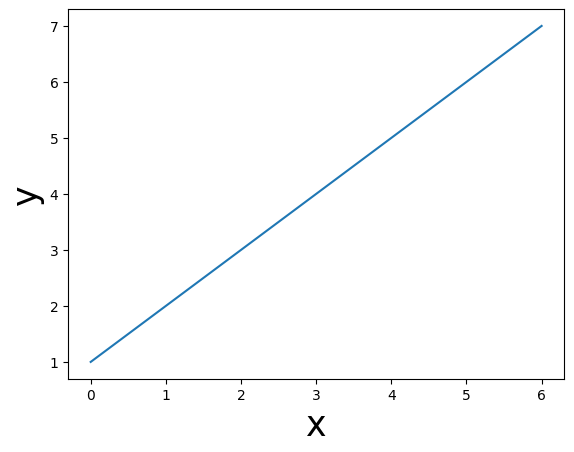

In [ ]:
x = [0, 1, 2, 3, 4, 5, 6]
y = [1, 2, 3, 4, 5, 6, 7]

plt.plot(x, y)  # plot the data
plt.xlabel('x', fontsize=25)  # set the x-axis label
plt.ylabel('y', fontsize=25)  # set the y-axis label
plt.show()  # this actually visualizes the plot

As you can see, the state-based approach entails a series of function calls (such as `plt.plot` and `plt.xlabel`). After you are done plotting, you just call `plt.show` and the plot will show in your notebook (or an external image viewer if you run it from a script). Note that, technically, the `plt.show` call is not necessary to render the plot in Jupyter notebooks, but we recommend doing it anyway as this is good practice.

The `plt.plot` function is perhaps the most basic function, which can be used to create any plot of paired datapoints (x, y). By default, it creates a line plot (as shown above), but the many (optional) parameters in `plt.plot` allow you to create many different variations! For example, instead of a line, we can plot the data as separate red points by specifying the format in the third argument (here, 'o' to indicate points) and the color (by setting the argument `c`, for **c**olor, to "red"):

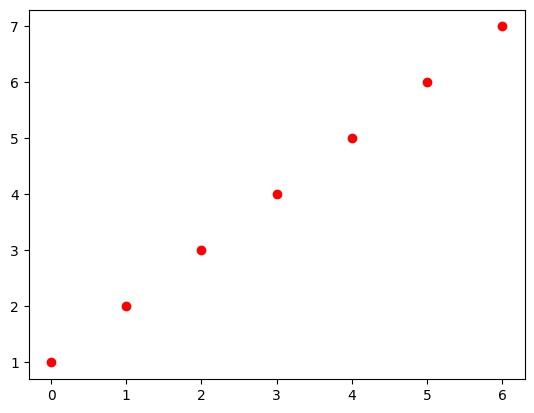

In [ ]:
plt.plot(x, y, 'o', c='red')
plt.show()

<div class='alert alert-success'>
    <b>Tip</b>: Note that the third argument, the "format", may be used to specify three things at once: whether you want "markers" (and which type of marker), whether you want a line (and which type of line), and which color the markers/line should have. So, to create red markers, you may specify "or" ("o" for circles as markers and "r" for red). To create a blue line, you may specify "-b". To create a yellow ("y") dotted line ("-.") with stars ("*") as markers, you may use "*-.y".
</div>

<div class='alert alert-warning'>
    <b>ToDo</b>: Create the same plot as above, but with a green dashed line with diamonds as markers. Check out the <a href="https://matplotlib.org/api/_as_gen/matplotlib.pyplot.plot.html">plt.plot</a> documentation under "Notes" which particular linestyle you need for this! And check <a href="https://matplotlib.org/api/markers_api.html">this page</a> to see the name of the marker for diamonds! Make sure to write your code <b>above</b> the "<tt>ax2check = plt.gca()</tt>" snippet &mdash; we use this to check your plot automatically in the test cell! Also, do not include a <tt>plt.show</tt> call; this is done after the <tt>ax2check</tt> line (calling <tt>plt.show</tt> before <tt>ax2check</tt> will cause to test cell to malfunction).
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

# Do not remove the code below!
ax2check = plt.gca()
plt.show()

In [ ]:
""" Tests the ToDo above. """
line = ax2check.get_lines()[0]
if not line._color in ['g', 'green']:
    raise ValueError("The line is not green!")

if line._linestyle != '--':
    raise ValueError("You didn't use a dashed line!")

if line._marker._marker != 'D':
    raise ValueError("You didn't use diamonds!")

print("Yay! Well done.")

You can also plot multiple things within a single plot! Just call the `plt.plot` (or any other plotting function) multiple times. Below, we create a new variable (`y_sq`, the values of squared) and plot it in the same plot as our regular (x, y) plot. Importantly, we will include legend with the plot showing what each line represents using `plt.legend`:

In [ ]:
y_sq = [yi ** 2 for yi in y]  # check out this list comprehension!

plt.plot(x, y, '*b')  # only plot markers (*) in blue
plt.plot(x, y_sq, '^--y')  # plot both markers (^) and a line (--) in yellow

# Note that the plt.legend function call should come *after* the plotting calls
# and you should give it a *list* with strings
plt.legend(['y', 'y squared'])
plt.show()

<div class='alert alert-danger'>
    <b>Warning</b>: Importantly, in the context of Jupyter notebooks, each part of the plot should be defined in the same code cell; otherwise, they won't be included in the same figure.
</div>

As you can see, Matplotlib automatically creates the right legend! Make sure that the order of your labels (here: `['y', 'y squared']`) matches the order of your plotting calls!

<div class='alert alert-success'>
    <b>Good to know</b>: If you plot multiple things in the same plot, Matplotlib will automatically choose a different color for the different things (first one is blue, second one is orange, third one is green, etc.).
</div>

<div class='alert alert-warning'>
    <b>ToDo</b>: Below, we define some new variables: <tt>z</tt>, the sine of z (<tt>sin_z</tt>), and the cosine of z (<tt>cos_z</tt>). Plot both the (<tt>z</tt>, <tt>sin_z</tt>) and (<tt>z</tt>, <tt>cos_z</tt>) collections as separate dashed lines in whatever (different) colors you like. Make sure to add a legend!
</div>

In [ ]:
""" Implement your ToDo below. """
import math
z = [zi / 10 for zi in list(range(100))]
sin_z = [math.sin(zi) for zi in z]
cos_z = [math.cos(zi) for zi in z]

# YOUR CODE HERE
raise NotImplementedError()

# Do not remove the code below and implement your code *above* this snippet
ax2check = plt.gca()
plt.show()

In [ ]:
""" Tests the ToDo above. """
lines = ax2check.get_lines()
if len(lines) != 2:
    raise ValueError(f"I expected 2 lines but found {len(lines)}!")

leg = ax2check.get_legend()
if leg is None:
    raise ValueError("You didn't include a legend!")

n_leg = len(leg.get_lines())
if n_leg != 2:
    raise ValueError("I expected two things in the legend but found {n_leg}!")

print("Good job!")

There are several other things that you can add to or tweak in your plot. For example, you can add a title with `plt.title` or you can change the default ticks and tick labels using `plt.xticks` (for the x-axis ticks/tick labels) and `plt.yticks` (for the y-axis ticks/tick labels). An example:

In [ ]:
plt.title("Plot with modified x-axis ticks and tick labels!", fontsize=14)
plt.plot(x, y)
plt.xticks([0, 2, 4, 6], ['0th', '2nd', '4th', '6th'])
plt.show()

And you can control the range of the axes by the functions `plt.xlim` and `plt.ylim`:

In [ ]:
plt.plot(x, y)
plt.xlim(-5, 12)
plt.ylim(-5, 12)
plt.show()

### Different plot functions
Of course, `plt.plot` is not the only plotting functions! There are many different plotting functions in Matplotlib, including scatterplots:

In [ ]:
plt.title("A scatterplot!", fontsize=20)
# Note that this is equivalent to plt.plot(x, y, 'o') !
plt.scatter(x, y)
plt.show()

... and bar graphs:

In [ ]:
# First argument determines the location of the bars on the x-axis
# and the second argument determines the height of the bars
plt.bar(x, x)
plt.show()

... and histograms:

In [ ]:
# Let's generate some random data
import random
random_unif = [random.uniform(0, 1) for _ in range(100)]

plt.title("A histogram!", fontsize=20)
plt.hist(random_unif)
plt.xlabel("Value", fontsize=15)
plt.ylabel("Frequency", fontsize=15)
plt.show()

<div class='alert alert-warning'>
    <b>ToDo</b>: Below, we again simulate some random data, but this time not from a uniform distribution, but from a normal distribution (with mean 0.5 and a standard deviation of 0.15). Plot both the uniform data (<tt>random_unif</tt>) and the normal data (<tt>random_norm</tt>) in the same plot, but with different colors (doesn't matter which). Make sure to use 10 bins for each histogram and make sure they are slightly transparent by setting the "alpha" level to 0.5 in both. Also, make sure the ticks and xtick labels are spaced 0.1 apart (i.e., a tick and label at 0, at 0.1, ..., until 1.0). And add a legend! To find out how to set the number of bins and the alpha level, check out the <a href="https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.pyplot.hist.html">documentation</a>!
</div>

In [ ]:
""" Implement the ToDo here! """
random_norm = [random.normalvariate(0.5, 0.15) for _ in range(100)]
import numpy as np
# YOUR CODE HERE
raise NotImplementedError()

# Do not remove the code below
ax2check = plt.gca()
plt.show()

In [ ]:
""" Tests the ToDo above. """
import matplotlib
rect = [ch for ch in ax2check.get_children() if ch.__class__ == matplotlib.patches.Rectangle]
if len(rect) != 21:
    raise ValueError(f"I expected 20 bins in total (10 per histogram), but found {len(rect) - 1}!")

if rect[0]._alpha != 0.5:
    raise ValueError(f"The alpha level is not 0.5 (but {rect[0]._alpha})!")

leg = ax2check.get_legend()
if leg is None:
    raise ValueError("I couldn't find a legend!")


if len(ax2check.get_xticks()) != 11:
    raise ValueError("There should be 11 x-axis ticks and labels!")

xticks = ax2check.get_xticks()
if isinstance(xticks, np.ndarray):
    xticks = [round(xt, 1) for xt in xticks.tolist()]

if not xticks == [i / 10 for i in list(range(11))]:
    raise ValueError("The x-axis ticks and tick labels are not yet correct ...")

print("Awesome!")

## The object-oriented interface
The state-based plotting approach is easy to learn and pretty straightforward, but when you start creating more complex visualizations, you'll notice that the alternative "object-oriented" approach becomes easier to use. In this section, we will explain this approach by recreating some of the previous plots from the state-based section. We will also discuss some more advanced plotting techniques, such as creating subplots.

Now, within the object-oriented approach, we can explain some of the more technical (but important!) concepts. One of those is that each Matplotlib plot consists of a `Figure` object and one or more `Axes` objects. Essentially, the `Figure` object represents the entire canvas that defines the, well, figure. The `Axes` object(s) contains the actual visualizations that you want to include in the `Figure` (see figure below). Importantly, there may be one *or* multiple `Axes` object within a given `Figure` (e.g., two line plots next to each other).

![mpl2](https://files.realpython.com/media/fig_map.bc8c7cabd823.png)

*Figure from Brad Solomon, from [https://realpython.com/python-matplotlib-guide/](https://realpython.com/python-matplotlib-guide/)*

<div class='alert alert-danger'>
    <b>Warning</b>: Note that an <tt>Axes</tt> object is something different than the x-axis and y-axis ("axes") of a plot!
</div>

Importantly, a `Figure` object by itself doesn't do anything. It just defines the canvas to drawn on, so to speak. `Figure` objects can be initialized using `plt.figure`, which takes several (optional) arguments like `figsize` (width and height in inches) and `dpi` ("dots per inch", i.e., resolution). Let's take a look:

In [ ]:
fig = plt.figure(figsize=(8, 4))
plt.show()

As you can see, nothing happens. We also need an `Axes` object! We can create this using `plt.axes`. Note that, even in the object-oriented appoach, we need the function `plt.show` to render the figure.

In [ ]:
fig = plt.figure(figsize=(8, 4))
ax = plt.axes()
plt.show()

Instead of creating the `Figure` and `Axes` objects separately, we highly recommend using the function `plt.subplots` to create them both at the same time. Like the name suggests, this function also allows you to create multiple subplots (across different `Axes`), which we'll discuss later. For now, we'll just use it to create a `Figure` and `Axes` object at once. Note that all arguments for creating `Figures` using `plt.figure` also work for `plt.subplots`. For example, you can give `plt.subplots` the arguments `figsize=(8, 4)` and `dpi=200` (these must be specified with keywords, however)! Check out the [full documentation] of `plt.subplots` to get an idea about the different arguments it accepts.

Anyway, let's take a look:

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
plt.show()

Alright, great, but it's still an empty canvas! Now, we could of course plot some data using the state-based interface (e.g., `plt.plot(x, y)`). Here, however, we will use the object-oriented approach. The only difference between these two approaches is that plotting in the object-oriented approach is done through the *methods* of the `Ax` object instead of the functions from the `pyplot` module. An example:

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)  # here, `plot` is a method, not a function!
plt.show()

Basically all functions from the state-based interface are available as methods in the object-oriented approach. For example, to create a legend, run `ax.legend` (instead of `plt.legend`):

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)
ax.plot(x, y_sq)
ax.legend(['y', 'y squared'])
plt.show()

Some `pyplot` functions (like `plt.xlabel`), however, are prefixed with `set_` in the object-oriented interface (e.g., `ax.set_xlabel`):

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, y)
ax.set_xlabel('x', fontsize=15)
ax.set_ylabel('y', fontsize=15)
ax.set_title("Some plot", fontsize=20)
plt.show()

Okay, time for an exercise!

<div class='alert alert-warning'>
    <b>ToDo</b>: Below, using a so-called "random walk", we create some random numbers representing two time series. Let's pretend that this data represents the stock price of two companies (Tesla and Shell) across 100 consecutive days. Create a <tt>Figure</tt> of 12 (width) by 4 (height) inches and a single <tt>Axes</tt> onto which you plot this time series data (as lines). Label the axes appropriately and set the range of the x-axis from 1 to 100.
</div>

In [ ]:
""" Implement the ToDo here. """
steps1 = [random.uniform(-1, 1) for _ in range(100)]
steps2 = [random.uniform(-1, 1) for _ in range(100)]

tesla = [40 + sum(steps1[:i]) for i in range(100)]
shell = [35 + sum(steps2[:i]) for i in range(100)]
days = list(range(1, 101))

# YOUR CODE HERE
raise NotImplementedError()

# Do not remove the code below
ax2check = plt.gca()
plt.show()

In [ ]:
""" Tests the above ToDo. """
lines = ax2check.get_lines()
if len(lines) != 2:
    raise ValueError(f"I expected two lines, but I saw {len(lines)}!")

if ax2check.get_legend() is None:
    raise ValueError("There is no legend!")

if not ax2check.get_xlabel():
    raise ValueError("There is no label for the x-axis!")

if not ax2check.get_ylabel():
    raise ValueError("There is no label for the y-axis!")

print("YES! Well done!")

Okay, one last thing we want to show you is how to save figures to disk! In the object-oriented interface, you can save figures using the `Figure` method `savefig` (check out its [documentation](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.savefig.html)). The only mandatory argument is a filename, including an extension. The extension determines as which file type the figure is saved. If you want to save a figure as a PNG file, you can for example do the following:

In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(x, y)
plt.show()
fig.savefig('my_awesome_figure.png')

This actually created a new file, "my_awesome_figure.png", in our current directory. We can double-check this using the command `!ls`, which is some Jupyter magic that allows us to use a code cell as a terminal temporarily:

In [ ]:
!ls

## Subplots (optional)
In this optional section, we will discuss figures with "subplots", i.e., figures with more than one `Axes` object! The easiest way to do this is to use the `plt.subplots` function. This function accepts the arguments `ncols` and `nrows` to create a figure with multiple `Axes` next to each other (`ncols` > 1) or below each other (`nrows` > 1). For example, suppose that I want to create a figure with three plots next to each other:

In [ ]:
# Note that I use the variable name "axes" here instead of "ax" like before
# This is not necessary, but I find it helpful because it tells me this variable contains
# more than one axis
fig, axes = plt.subplots(ncols=3, figsize=(15, 4))
plt.show()

The variable `axes` is slightly different from what we've seen before. Let's check out its type:

In [ ]:
type(axes)

When you create a figure with more than one `Axes` object, the function `plt.subplots` returns a so-called *numpy* ndarray with `Axes` ("ndarray" stands for *N*-dimensional array). Numpy arrays are data structures that we discuss at length in the last section. For now, you can interpret numpy arrays as (in this case) one or two-dimensional lists. To access the individual `Axes` objects from the numpy array, we can index them as if they are lists. For example:

In [ ]:
first_ax = axes[0]

NameError: name 'axes' is not defined

Now, let's plot some stuff in our different `Axes` objects.

In [ ]:
fig, axes = plt.subplots(ncols=3, figsize=(15, 4))
axes[0].plot(x, y)
axes[1].plot(x, [yi ** 2 for yi in y])
axes[2].plot(x, [yi ** 3 for yi in y])
names = ['y', 'y squared', 'y cubed']
for i, name in enumerate(names):
    axes[i].set_title(name, fontsize=20)

plt.show()

<div class='alert alert-warning'>
    <b>ToDo</b>: As you probably have noticed by now, if you don't explicitly give Matplotlib a range for the axes (using <tt>xlim</tt> and <tt>ylim</tt>), it will chose a suitable range itself, which results in separate ranges for the subplots in the above figure. To force the same range across subplots, set the arguments <tt>sharex</tt> and/or <tt>sharey</tt> to <tt>True</tt> in the <tt>plt.subplots</tt> call. Do this in the previous code cell to force the same range across the y-axes!
</div>

We can, of course, create figures with multiple columns *and* multiple rows. For example, to create a 2 by 2 grid of `Axes`, we can do the following:

In [ ]:
fig, axes = plt.subplots(ncols=2, nrows=2, figsize=(5, 5))
plt.show()

<div class='alert alert-success'>
    <b>Tip</b>: Sometimes, like in the figure above, subplots may overlap slightly, especially in small figures. Matplotlib has a neat function to fix this: <tt>plt.tight_layout</tt>. Try adding it to the code cell above (after the <tt>plt.subplots</tt> line but before the <tt>plt.show()</tt> line).
</div>

Currently, the `axes` variable is a two-dimensional numpy array (because it has both multiple columns and multiple rows). We can double-check this by checking out the `shape` attribute from the numpy array:

In [ ]:
axes.shape

Now, to access the individual `Axes` objects from this numpy array, we need two indices: one to indicate the row and one to indicate the column. For example, to get the upper left `Axes` object (i.e., first row, first column), we do:

In [ ]:
upper_left_ax = axes[0, 0]

To get the upper right `Axes` object (i.e., first row, second column), we do:

In [ ]:
upper_right_ax = axes[0, 1]

<div class='alert alert-warning'>
    <b>ToDo</b>: Extract the lower right <tt>Axes</tt> object and store it in a variable named <tt>lower_right_ax</tt>
</div>

In [ ]:
""" Implement the ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

In [ ]:
""" Tests the above ToDo. """
if lower_right_ax != axes.flatten()[-1]:
    raise ValueError("That is not the correct Axes object ...")

print("Well done!")

Alright, there is not much more to subplots that we explained here! Let's finish with a difficult exercise for those that want a challenge. From trigonometry, you may remember we can how to create a sine wave with a particular amplitude and frequency. Below, we included a function, `create_sine_wave`, which takes in a list of timepoints, a desired frequecy, and a desired amplitude:

In [ ]:
def create_sine_wave(timepoints, frequency=1, amplitude=1):
    """ Creates a sine wave with a given frequency and amplitude for a given set of timepoints.

    Parameters
    ----------
    timepoints : list
        A list with timepoints (assumed to be in seconds)
    frequency : int/float
        Desired frequency (in Hz.)
    amplitude : int/float
        Desired amplitude (arbitrary units)

    Returns
    -------
    sine : list
        A list with floats representing the sine wave
    """
    sine = [amplitude * math.sin(2 * math.pi * frequency * t) for t in timepoints]
    return sine

Given some timepoints, we can plot its corresponding sine wave:

In [ ]:
timepoints = [i / 100 for i in range(500)]
sine = create_sine_wave(timepoints)

fig, ax = plt.subplots(figsize=(8, 2))
ax.plot(timepoints, sine)
ax.set_xlabel("Time")
ax.set_ylabel("sin(x)")
ax.set_xlim(0, max(timepoints))
plt.show()

We already created a quite complicated figure with 9 subplots (3 rows, 3 columns), which shows a sine wave with increasing frequencies (1, 3, 5) across columns and increasing amplitudes across rows (1, 2, 4). We'll show this figure below:

![sines](solution_sine_wave_plot.png)

<div class='alert alert-warning'>
    <b>ToDo</b>: Try to recreate the figure above with your own code! Use a <tt>figsize</tt> of (10, 10). Good luck! (No test cell)
</div>

In [ ]:
""" Implement your ToDo here. """
# YOUR CODE HERE
#raise NotImplementedError()

---
## Module: Scipy
_Source: from https://phoenixnap.com/kb/scipy-tutorial_



**What is SciPy?**

SciPy (Scientific Python) is an open-source scientific computing module for Python. Based on NumPy, SciPy includes tools to solve scientific problems. Scientists created this library to address their growing needs for solving complex issues.

**SciPy vs NumPy**

The NumPy library (Numerical Python) does numerical computation. Scientists use this library for working with arrays since NumPy covers elementary uses in data science, statistics, and mathematics.

SciPy covers advanced calculations and functions. This library adds more data science features, all linear algebra functions, and standard scientific algorithms.

---
However, we will just have a quick look on what scipy is, so you have seen it before. In the upcoming section scipy will occasionally pop up and applying it in the context of the exercise will makes more sense then spending another section on it.

**SciPy Subpackages**

The SciPy library has different groups of subpackages. There are two ways to import subpackages from the SciPy module:

In [ ]:
import scipy.<sub package name> as <alias>

In [ ]:
from scipy import <sub package name> as <alias>

For example:

In [47]:
import scipy.special as spec

Now you can use the funntions of the "special" subpackage of the scipy package.

For example, to find the factorial of ten, use:

In [48]:
print(spec.factorial(10))


3628800.0


Alternatively you can import the top-level scipy package (by convention you do this with "import scipy as sp") and then specify the subpackage you are using.

In [49]:
import scipy as sp
print(sp.special.factorial(10))

3628800.0


Depending on what you need from scipy, just loading subpackages is sometimes smarter.

**help()**

Of course, there a many those subpackages and functions. If you want more information on these, you can call them using help(). Like this

In [31]:
help(special.factorial)

Help on function factorial in module scipy.special._basic:

factorial(n, exact=False, extend='zero')
    The factorial of a number or array of numbers.

    The factorial of non-negative integer `n` is the product of all
    positive integers less than or equal to `n`::

        n! = n * (n - 1) * (n - 2) * ... * 1

    Parameters
    ----------
    n : int or float or complex (or array_like thereof)
        Input values for ``n!``. Complex values require ``extend='complex'``.
        By default, the return value for ``n < 0`` is 0.
    exact : bool, optional
        If ``exact`` is set to True, calculate the answer exactly using
        integer arithmetic, otherwise approximate using the gamma function
        (faster, but yields floats instead of integers).
        Default is False.
    extend : string, optional
        One of ``'zero'`` or ``'complex'``; this determines how values ``n<0``
        are handled - by default they are 0, but it is possible to opt into the
        complex

As you can see, it gives you a brief description and an example.



You can also just call help() without an argument, which guides you to search bar, where you can search for specific function. By typing **scipy.speical. factorial** into it you will be guided to a the same info page. You can try it out if you want to.

In [40]:
help()

Welcome to Python 3.12's help utility! If this is your first time using
Python, you should definitely check out the tutorial at
https://docs.python.org/3.12/tutorial/.

Enter the name of any module, keyword, or topic to get help on writing
Python programs and using Python modules.  To get a list of available
modules, keywords, symbols, or topics, enter "modules", "keywords",
"symbols", or "topics".

Each module also comes with a one-line summary of what it does; to list
the modules whose name or summary contain a given string such as "spam",
enter "modules spam".

To quit this help utility and return to the interpreter,
enter "q" or "quit".


You are now leaving help and returning to the Python interpreter.
If you want to ask for help on a particular object directly from the
interpreter, you can type "help(object)".  Executing "help('string')"
has the same effect as typing a particular string at the help> prompt.


**scipy.stats**

One of the most frequently used subpackages in scipy is the stats package. It is including many handy statistical test you can run on your data. Let’s have a look on this example comparing these two data sets (stored as a numpy array) using a independent samples t-test.

In [50]:
import numpy as np
import scipy.stats as stats

# Sample data
group_A = np.array([85, 88, 90, 75, 95, 80, 79, 92])
group_B = np.array([78, 82, 84, 70, 76, 85, 80, 79])

# 1️⃣ Calculate basic stats
print("Group A mean:", np.mean(group_A))
print("Group B mean:", np.mean(group_B))

# 2️⃣ Perform an independent samples t-test
t_stat, p_value = stats.ttest_ind(group_A, group_B)

print("\nT-statistic:", t_stat)
print("P-value:", p_value)

# 3️⃣ Interpret the result
alpha = 0.05  # significance level (5%)
if p_value < alpha:
    print("\n✅ The difference is statistically significant (reject H₀).")
else:
    print("\n❌ No significant difference (fail to reject H₀).")

Group A mean: 85.5
Group B mean: 79.25

T-statistic: 2.084367502338864
P-value: 0.055925685125530866

❌ No significant difference (fail to reject H₀).


As you can see, we can use the function ttest_ind() from the stats subpackage to run an independent samples t-test.

It would not make sense to dive deeper into this. But you are going to see that scipy will appear many times in data analysis tasks and familiarizing yourself with it is beneficial.